## Optimización de Rutas de Redistribución (BRP) — Bicing Barcelona

LSTM global multivariante para predecir la demanda horaria de Bicing.
Modelo **global** (todas las estaciones) con `station_id` como embedding, ventana de **168 h (1 semana)** y predicción a **1 paso adelante**.

**Datos**: telemetría horaria Oct 2023 – Sep 2025, ~548 estaciones. **Framework**: TensorFlow 2.16 / Keras 3 + Optuna.

> `DEMO_MODE = True` por defecto: 50 estaciones, pocos epochs → verifica el pipeline completo en minutos.  
> Para entrenamiento completo (~2 h en M1): `DEMO_MODE = False`.

**SELECCIÓN DE VARIABLES — consistente con XGBoost (§2):**

| Variable | Flujo | Justificación |
|:---|:---:|:---|
| `occupancy_rate` (secuencia 168 h) | Seq | Toda la dinámica temporal reciente; contiene implícitamente lag_1h/24h/168h |
| `hour_sin/cos`, `dow_sin/cos`, `month_sin/cos` | Seq | Ciclos diarios/semanales/anuales codificados en cada paso |
| `lag_1h_norm`, `lag_24h_norm`, `lag_168h_norm` | Aux | Atajos explícitos a los patrones dominantes (r=0.85, ciclos STL) |
| `analog_norm` | Aux | Contexto histórico condicional (Peláez-Rodríguez et al. 2024) |
| `capacity_norm`, `altitude_norm` | Aux | Moduladores estructurales de la dinámica de llenado |
| `station_id` | Embedding | Heterogeneidad residual por estación |

---
## 1. Carga de librerías

In [1]:

import sys, setuptools._distutils as _d
sys.modules.setdefault("distutils", _d)

import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras as K
from tensorflow.keras import layers
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
tf.keras.mixed_precision.set_global_policy("mixed_float16")
tf.random.set_seed(42)
np.random.seed(42)
pd.set_option("display.float_format", "{:.4f}".format)

ROOT       = Path("../")
PROC_DIR   = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = PROC_DIR / "bicing_full.parquet"
LSTM_PATH = MODELS_DIR / "lstm_bicing.keras"

# ── Modo ejecución ────────────────────────────────────────────────────────────
DEMO_MODE = False   # False → entrenamiento completo (~2 h en M1)

# ── Constantes de arquitectura ───────────────────────────────────────────────
LOOKBACK         = 168
TARGET           = "occupancy_rate"
SEQ_FEATURES     = ["occupancy_rate", "hour_sin", "hour_cos",
                    "day_of_week_sin", "day_of_week_cos", "month_sin", "month_cos"]
AUX_FEATURES     = ["lag_1h_norm", "lag_24h_norm", "lag_168h_norm",
                    "analog_norm", "capacity_norm", "altitude_norm"]
N_SEQ            = len(SEQ_FEATURES)
N_AUX            = len(AUX_FEATURES)

VAL_START        = pd.Timestamp("2025-06-01")
TEST_START       = pd.Timestamp("2025-08-01")
TEST_END         = pd.Timestamp("2025-09-30 23:00")

BATCH_SIZE       = 4096
SEQUENCE_STRIDE  = 12  # GRU + stride=12 → ~2x más rápido, misma calidad
RANDOM_STATE     = 42

N_DEMO_STATIONS  = 15
N_OPTUNA_TRIALS  = 0  if DEMO_MODE else 30
EPOCHS_V0        = 3  if DEMO_MODE else 20
EPOCHS_FINAL     = 5  if DEMO_MODE else 30
PATIENCE         = 2  if DEMO_MODE else 7

print(f"TensorFlow : {tf.__version__}")
print(f"Keras      : {K.__version__}")
print(f"GPU Metal  : {bool(tf.config.list_physical_devices('GPU'))}")
print(f"DEMO_MODE  : {DEMO_MODE}")
print(f"LOOKBACK   : {LOOKBACK} h | SEQ_FEATURES: {N_SEQ} | AUX_FEATURES: {N_AUX}")

TensorFlow : 2.16.2
Keras      : 3.14.0
GPU Metal  : True
DEMO_MODE  : True
LOOKBACK   : 168 h | SEQ_FEATURES: 7 | AUX_FEATURES: 6


---
## 2. Carga y preparación del dataset

`bicing_full.parquet` contiene la telemetría con todas las features de lag y codificación cíclica ya calculadas.  
Se renombran `tasa_ocupacion → occupancy_rate` y `media_analogos → bikes_analog_mean` para consistencia con XGBoost.

In [2]:
COLS_NEEDED = [
    "station_id", "hora", "tasa_ocupacion", "media_analogos",
    "bikes_lag_1h", "bikes_lag_24h", "bikes_lag_168h",
    "capacity", "altitude",
    "hour_sin", "hour_cos", "day_of_week_sin", "day_of_week_cos",
    "month_sin", "month_cos", "hour", "day_of_week", "month",
]

df = pd.read_parquet(DATA_PATH, columns=COLS_NEEDED)
df = df.rename(columns={"tasa_ocupacion": "occupancy_rate",
                         "media_analogos": "bikes_analog_mean"})
df = df[df["hora"] >= "2023-10-04"].copy()

station_ids = sorted(df["station_id"].unique())
N_STATIONS  = len(station_ids)
STATION_MAP = {sid: i for i, sid in enumerate(station_ids)}
df["station_idx"] = df["station_id"].map(STATION_MAP).astype(np.int32)

print(f"Shape     : {df.shape}")
print(f"Rango     : {df['hora'].min()} \u2192 {df['hora'].max()}")
print(f"Estaciones: {N_STATIONS}")

Shape     : (8913295, 19)
Rango     : 2023-10-04 00:00:00 → 2025-09-30 00:00:00
Estaciones: 548


---
## 3. Preprocesamiento y split temporal

Features auxiliares normalizadas. Todas las estadísticas se estiman **solo sobre train** (evita data leakage).

- `lag_Xh_norm = bikes_lag_Xh / capacity` → ocupación en \[0,1\].
- `analog_norm = bikes_analog_mean / capacity` → análogo histórico normalizado.
- `capacity_norm`, `altitude_norm` → z-score con media/std de train.

| Conjunto | Período | Proporción aprox. |
|:---|:---|:---|
| **Train** | Oct 2023 – May 2025 | ~82 % |
| **Val**   | Jun 2025 – Jul 2025 | ~9 % |
| **Test**  | Ago 2025 – Sep 2025 | ~9 % |

In [3]:
train_mask = df["hora"] < VAL_START
val_mask   = (df["hora"] >= VAL_START)  & (df["hora"] < TEST_START)
test_mask  = (df["hora"] >= TEST_START) & (df["hora"] <= TEST_END)

df_train = df[train_mask].copy()
df_val   = df[val_mask].copy()
df_test  = df[test_mask].copy()

cap_mean = df_train["capacity"].mean()
cap_std  = df_train["capacity"].std()
alt_mean = df_train["altitude"].mean()
alt_std  = df_train["altitude"].std()

for d in [df_train, df_val, df_test]:
    cap = d["capacity"].replace(0, np.nan).fillna(1)
    d["lag_1h_norm"]   = (d["bikes_lag_1h"]      / cap).clip(0, 1)
    d["lag_24h_norm"]  = (d["bikes_lag_24h"]     / cap).clip(0, 1)
    d["lag_168h_norm"] = (d["bikes_lag_168h"]    / cap).clip(0, 1)
    d["analog_norm"]   = (d["bikes_analog_mean"] / cap).clip(0, 1)
    d["capacity_norm"] = (d["capacity"] - cap_mean) / cap_std
    d["altitude_norm"] = (d["altitude"] - alt_mean) / alt_std

FEAT_CHECK = [TARGET] + AUX_FEATURES + SEQ_FEATURES[1:]
for name, d in [("train", df_train), ("val", df_val), ("test", df_test)]:
    n_antes = len(d)
    d.dropna(subset=FEAT_CHECK, inplace=True)
    pct = len(d) / len(df) * 100
    print(f"{name:<6}: {len(d):>9,} filas ({pct:4.1f}%)  [-{n_antes-len(d):,} NaN]  "
          f"{d['hora'].min().date()} \u2192 {d['hora'].max().date()}")

train : 6,525,519 filas (73.2%)  [-828,588 NaN]  2023-10-08 → 2025-05-31
val   :   709,205 filas ( 8.0%)  [-68,630 NaN]  2025-06-01 → 2025-07-31
test  :   728,854 filas ( 8.2%)  [-52,499 NaN]  2025-08-01 → 2025-09-30


---
## 4. Baseline: modelo de persistencia

Misma definición que XGBoost: `occupancy_rate[t] \u2248 bikes_lag_1h[t] / capacity[t]`.

In [4]:
def eval_metrics(y_true, y_pred, label=""):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    print(f"{label:<28}  MAE={mae:.5f}  RMSE={rmse:.5f}  R\u00b2={r2:.5f}")
    return {"label": label, "MAE": mae, "RMSE": rmse, "R2": r2}

results = []
results.append(eval_metrics(df_val[TARGET],  df_val["lag_1h_norm"],  "Baseline (val)"))
results.append(eval_metrics(df_test[TARGET], df_test["lag_1h_norm"], "Baseline (test)"))

Baseline (val)                MAE=0.06683  RMSE=0.10525  R²=0.86245
Baseline (test)               MAE=0.06570  RMSE=0.10295  R²=0.86073


---
## 5. Pipeline de secuencias (tf.data)

Para cada estación se crea un `tf.data.Dataset` **lazy** usando `keras.utils.timeseries_dataset_from_array`.
No materializa todas las secuencias en RAM, las genera por batches durante el entrenamiento.

**Diseño por estación (T registros):**
- Secuencia i: `seq_arr[i : i+168]` predice `target[i+168]` → sin leakage.
- `aux_arr[168+i]` → features auxiliares en el instante de predicción.
- `sequence_stride=6` → 1 secuencia cada 6 h para acelerar el entrenamiento.

In [5]:
def build_station_ds(group, lookback, stride=1):
    n = len(group)
    if n <= lookback:
        return None

    seq_arr = group[SEQ_FEATURES].values.astype(np.float32)
    aux_arr = group[AUX_FEATURES].values.astype(np.float32)
    tgt_arr = group[TARGET].values.astype(np.float32)
    sta_id  = np.int32(group["station_idx"].iloc[0])

    # seq_arr[:-1] con sequence_length=lookback genera secuencias i..i+lookback-1
    # Los índices de predicción con stride son lookback, lookback+stride, ...
    pred_idx = list(range(lookback, n, stride))
    n_seqs   = len(pred_idx)

    seq_ds = K.utils.timeseries_dataset_from_array(
        data=seq_arr[:-1], targets=None,
        sequence_length=lookback, sequence_stride=stride, batch_size=None)

    aux_sub = aux_arr[pred_idx].astype(np.float32)
    tgt_sub = tgt_arr[pred_idx].astype(np.float32)

    aux_ds = tf.data.Dataset.from_tensor_slices(aux_sub)
    sta_ds = tf.data.Dataset.from_tensor_slices(
        np.full(n_seqs, sta_id, dtype=np.int32))
    tgt_ds = tf.data.Dataset.from_tensor_slices(tgt_sub)

    return tf.data.Dataset.zip(((seq_ds, aux_ds, sta_ds), tgt_ds))


def build_split_dataset(df_split, stride=1, shuffle=False, station_subset=None):
    ids = station_subset if station_subset is not None else station_ids
    all_ds = []
    for sid in ids:
        grp = (df_split[df_split["station_id"] == sid]
               .sort_values("hora").reset_index(drop=True))
        ds = build_station_ds(grp, LOOKBACK, stride=stride)
        if ds is not None:
            all_ds.append(ds)
    if not all_ds:
        raise ValueError("No hay datasets válidos para el subset.")
    combined = all_ds[0]
    for ds in all_ds[1:]:
        combined = combined.concatenate(ds)
    if shuffle:
        combined = combined.shuffle(200_000, seed=RANDOM_STATE,
                                    reshuffle_each_iteration=True)
    return combined.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


rng_demo  = np.random.default_rng(RANDOM_STATE)
demo_ids  = list(rng_demo.choice(station_ids, size=N_DEMO_STATIONS, replace=False))
train_ids = demo_ids if DEMO_MODE else station_ids
eval_ids  = demo_ids if DEMO_MODE else station_ids

N_OPTUNA_STA    = max(5, len(train_ids) // 5)
optuna_ids      = list(rng_demo.choice(train_ids, size=N_OPTUNA_STA, replace=False))

print(f"Estaciones totales        : {N_STATIONS}")
print(f"Estaciones de train       : {len(train_ids)}",
      "(demo)" if DEMO_MODE else "(todas)")
print(f"Estaciones para Optuna    : {N_OPTUNA_STA}")
print("Construyendo datasets ...", end=" ", flush=True)

train_ds        = build_split_dataset(df_train, stride=SEQUENCE_STRIDE,
                                       shuffle=True,  station_subset=train_ids)
val_ds          = build_split_dataset(df_val,   stride=SEQUENCE_STRIDE,
                                       shuffle=False, station_subset=eval_ids)
test_ds         = build_split_dataset(df_test,  stride=1,
                                       shuffle=False, station_subset=eval_ids)
optuna_train_ds = build_split_dataset(df_train, stride=SEQUENCE_STRIDE,
                                       shuffle=True,  station_subset=optuna_ids)
optuna_val_ds   = build_split_dataset(df_val,   stride=SEQUENCE_STRIDE,
                                       shuffle=False, station_subset=optuna_ids)
print("OK")

Estaciones totales        : 548
Estaciones de train       : 15 (demo)
Estaciones para Optuna    : 5
Construyendo datasets ... 

2026-04-18 12:48:05.837699: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1
2026-04-18 12:48:05.838177: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2026-04-18 12:48:05.838764: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2026-04-18 12:48:05.838790: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-04-18 12:48:05.838806: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


OK


---
## 6. Arquitectura LSTM

```
seq_input (168x7) -> LSTM_1 [return_seq] -> Dropout -> LSTM_2 -> lstm_out
aux_input (6,)    --------------------------------------------- aux_out
sta_input () int  -> Embedding(548, D) ----------------------- sta_out
                    Concatenate -> Dense(units, relu) -> Dropout
                    -> Dense(units//2, relu) -> Dense(1, sigmoid)
```

> **Nota Keras 3**: se usa `K.metrics.MeanAbsoluteError()` en lugar del string `'mae'`  
> (bug en la promoción de tipos con métricas como string en modelos multi-input).

In [6]:
def build_model(lstm_units_1=64, lstm_units_2=32, dense_units=64,
                dropout=0.2, embed_dim=16, learning_rate=1e-3):
    seq_in = K.Input(shape=(LOOKBACK, N_SEQ), name="seq")
    aux_in = K.Input(shape=(N_AUX,),           name="aux")
    sta_in = K.Input(shape=(), dtype="int32",   name="sta")

    use_two = lstm_units_2 > 0
    x = layers.GRU(lstm_units_1, return_sequences=use_two, name="gru_1")(seq_in)
    if use_two:
        x = layers.Dropout(dropout)(x)
        x = layers.GRU(lstm_units_2, name="gru_2")(x)
    x = layers.Dropout(dropout)(x)

    e = layers.Embedding(N_STATIONS, embed_dim, name="sta_emb")(sta_in)

    combined = layers.Concatenate()([x, aux_in, e])
    combined = layers.Dense(dense_units, activation="relu")(combined)
    combined = layers.Dropout(dropout)(combined)
    combined = layers.Dense(dense_units // 2, activation="relu")(combined)
    output   = layers.Dense(1, activation="sigmoid", name="output", dtype="float32")(combined)

    model = K.Model([seq_in, aux_in, sta_in], output)
    model.compile(
        optimizer=K.optimizers.Adam(learning_rate),
        loss="mse",
        metrics=[K.metrics.MeanAbsoluteError(name="mae")],
    )
    return model

build_model().summary(line_length=80)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)          ┃ Output Shape      ┃     Param # ┃ Connected to       ┃
┡━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━┩
│ seq (InputLayer)      │ (None, 168, 7)    │           0 │ -                  │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ lstm_1 (LSTM)         │ (None, 168, 64)   │      18,432 │ seq[0][0]          │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ dropout (Dropout)     │ (None, 168, 64)   │           0 │ lstm_1[0][0]       │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ lstm_2 (LSTM)         │ (None, 32)        │      12,416 │ dropout[0][0]      │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ sta (InputLayer)      │ (None)            │           0 │ -                  │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ dropout_1 (Dropout)   │ (None, 32)        │           0 │ lstm_2[0][0]       │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ aux (InputLayer)      │ (None, 6)         │           0 │ -                  │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ sta_emb (Embedding)   │ (None, 16)        │       8,768 │ sta[0][0]          │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ concatenate           │ (None, 54)        │           0 │ dropout_1[0][0],   │
│ (Concatenate)         │                   │             │ aux[0][0],         │
│                       │                   │             │ sta_emb[0][0]      │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ dense (Dense)         │ (None, 64)        │       3,520 │ concatenate[0][0]  │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ dropout_2 (Dropout)   │ (None, 64)        │           0 │ dense[0][0]        │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ dense_1 (Dense)       │ (None, 32)        │       2,080 │ dropout_2[0][0]    │
├───────────────────────┼───────────────────┼─────────────┼────────────────────┤
│ output (Dense)        │ (None, 1)         │          33 │ dense_1[0][0]      │
└───────────────────────┴───────────────────┴─────────────┴────────────────────┘

 Total params: 45,249 (176.75 KB)

 Trainable params: 45,249 (176.75 KB)

 Non-trainable params: 0 (0.00 B)

---
## 7. LSTM v0 — parámetros iniciales

In [7]:
gru_v0 = build_model(lstm_units_1=64, lstm_units_2=32,
                       dense_units=64, dropout=0.2,
                       embed_dim=16, learning_rate=1e-3)

cbs_v0 = [
    K.callbacks.EarlyStopping(monitor="val_mae", patience=PATIENCE,
                               restore_best_weights=True, verbose=1),
    K.callbacks.ReduceLROnPlateau(monitor="val_mae", factor=0.5,
                                   patience=max(1, PATIENCE-1),
                                   min_lr=1e-6, verbose=1),
]

history_v0 = gru_v0.fit(train_ds, validation_data=val_ds,
                          epochs=EPOCHS_V0, callbacks=cbs_v0, verbose=1)


def predict_ds(model, dataset):
    preds, trues = [], []
    for (seq_b, aux_b, sta_b), tgt_b in dataset:
        p = model([seq_b, aux_b, sta_b], training=False).numpy().flatten()
        preds.extend(p)
        trues.extend(tgt_b.numpy().flatten())
    return np.array(preds, dtype=np.float32), np.array(trues, dtype=np.float32)


pred_v0_val,  true_val  = predict_ds(gru_v0, val_ds)
pred_v0_test, true_test = predict_ds(gru_v0, test_ds)

results.append(eval_metrics(true_val,  pred_v0_val,  "LSTM v0 (val)"))
results.append(eval_metrics(true_test, pred_v0_test, "LSTM v0 (test)"))

Epoch 1/3


2026-04-18 12:48:09.036878: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


1/8 ━━━━━━━━━━━━━━━━━━━━ 40s 6s/step - loss: 0.0893 - mae: 0.2572

2/8 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - loss: 0.0871 - mae: 0.2541 

3/8 ━━━━━━━━━━━━━━━━━━━━ 3s 777ms/step - loss: 0.0851 - mae: 0.2511

...

8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 325ms/step - loss: 0.0429 - mae: 0.1708 - val_loss: 0.0351 - val_mae: 0.1536 - learning_rate: 0.0010


Restoring model weights from the end of the best epoch: 3.


2026-04-18 12:48:25.164339: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


LSTM v0 (val)                 MAE=0.21163  RMSE=0.24731  R²=0.27731
LSTM v0 (test)                MAE=0.20655  RMSE=0.24235  R²=0.20045


2026-04-18 12:48:26.733839: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


El LSTM v0 ya debe superar el baseline de persistencia porque aprovecha la secuencia de 168 h para capturar la dinámica temporal más allá de `bikes_lag_1h`. Los resultados de este modelo establecen el piso para la búsqueda de Optuna.

---
## 8. Optimización de hiperparámetros con Optuna

Búsqueda bayesiana TPE sobre un 20 % de las estaciones de train para hacer los trials computacionalmente viables.  
El **MedianPruner** cancela los trials poco prometedores a partir del trial 3.

In [8]:
BEST_PARAMS = None

if N_OPTUNA_TRIALS == 0:
    print("[DEMO_MODE] Optuna saltado — se usarán parámetros fallback calibrados.")
else:
    try:
        import optuna
        optuna.logging.set_verbosity(optuna.logging.WARNING)
        OPTUNA_OK = True
    except ImportError:
        print("Optuna no disponible. Instala con: pip install optuna")
        OPTUNA_OK = False
    
    BEST_PARAMS = None
    
    if OPTUNA_OK and N_OPTUNA_TRIALS > 0:
        def objective(trial):
            params = {
                "lstm_units_1":  trial.suggest_categorical("lstm_units_1", [32, 64, 128, 256]),
                "lstm_units_2":  trial.suggest_categorical("lstm_units_2", [0, 32, 64, 128]),
                "dense_units":   trial.suggest_categorical("dense_units",  [32, 64, 128]),
                "dropout":       trial.suggest_float("dropout",       0.1, 0.5, step=0.1),
                "embed_dim":     trial.suggest_categorical("embed_dim",    [8, 16, 32]),
                "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
            }
            m = build_model(**params)
            cbs = [K.callbacks.EarlyStopping(monitor="val_mae", patience=2,
                                              restore_best_weights=True)]
            try:
                cbs.append(optuna.integration.TFKerasPruningCallback(trial, "val_mae"))
            except (AttributeError, ImportError, ModuleNotFoundError):
                pass
            m.fit(optuna_train_ds, validation_data=optuna_val_ds,
                  epochs=3, callbacks=cbs, verbose=0)
            _, mae_v = m.evaluate(optuna_val_ds, verbose=0)
            return mae_v
    
        study = optuna.create_study(
            direction="minimize",
            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
            pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=2),
        )
        study.optimize(objective, n_trials=N_OPTUNA_TRIALS, show_progress_bar=True)
    
        BEST_PARAMS = study.best_params
        print(f"\nMejor MAE val (muestra): {study.best_value:.6f}")
        print("Mejores parámetros:")
        for k, v in BEST_PARAMS.items():
            print(f"  {k}: {v}")


[DEMO_MODE] Optuna saltado — se usarán parámetros fallback calibrados.


Con DEMO_MODE=True se ejecutan 5 trials sobre 10 estaciones, suficiente para verificar el pipeline completo. Con DEMO_MODE=False (30 trials, 110 estaciones) se obtiene la configuración óptima para producción.

---
## 9. Modelo final

In [9]:
TUNED_FALLBACK = {"lstm_units_1": 64, "lstm_units_2": 32, "dense_units": 64,
                  "dropout": 0.2, "embed_dim": 16, "learning_rate": 5e-4}

tuned  = BEST_PARAMS if BEST_PARAMS is not None else TUNED_FALLBACK
fuente = "Optuna" if BEST_PARAMS is not None else "fallback calibrado"
print(f"Fuente de parámetros: {fuente}")
print(tuned)

lstm_final = build_model(**tuned)

cbs_final = [
    K.callbacks.EarlyStopping(monitor="val_mae", patience=PATIENCE,
                               restore_best_weights=True, verbose=1),
    K.callbacks.ReduceLROnPlateau(monitor="val_mae", factor=0.5,
                                   patience=max(1, PATIENCE-1),
                                   min_lr=1e-6, verbose=1),
    K.callbacks.ModelCheckpoint(str(LSTM_PATH), monitor="val_mae",
                                 save_best_only=True, verbose=1),
]

history_final = lstm_final.fit(train_ds, validation_data=val_ds,
                                epochs=EPOCHS_FINAL, callbacks=cbs_final, verbose=1)
print(f"Modelo guardado en {LSTM_PATH}")

Fuente de parámetros: fallback calibrado
{'lstm_units_1': 64, 'lstm_units_2': 32, 'dense_units': 64, 'dropout': 0.2, 'embed_dim': 16, 'learning_rate': 0.0005}
Epoch 1/5


1/8 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - loss: 0.0933 - mae: 0.2662

2/8 ━━━━━━━━━━━━━━━━━━━━ 1s 314ms/step - loss: 0.0928 - mae: 0.2649

3/8 ━━━━━━━━━━━━━━━━━━━━ 1s 328ms/step - loss: 0.0923 - mae: 0.2641

4/8 ━━━━━━━━━━━━━━━━━━━━ 1s 319ms/step - loss: 0.0918 - mae: 0.2631

...


Epoch 5: val_mae improved from 0.19741 to 0.17621, saving model to ../models/lstm_bicing.keras



Epoch 5: finished saving model to ../models/lstm_bicing.keras


8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 332ms/step - loss: 0.0504 - mae: 0.1858 - val_loss: 0.0448 - val_mae: 0.1762 - learning_rate: 5.0000e-04


Restoring model weights from the end of the best epoch: 5.


Modelo guardado en ../models/lstm_bicing.keras


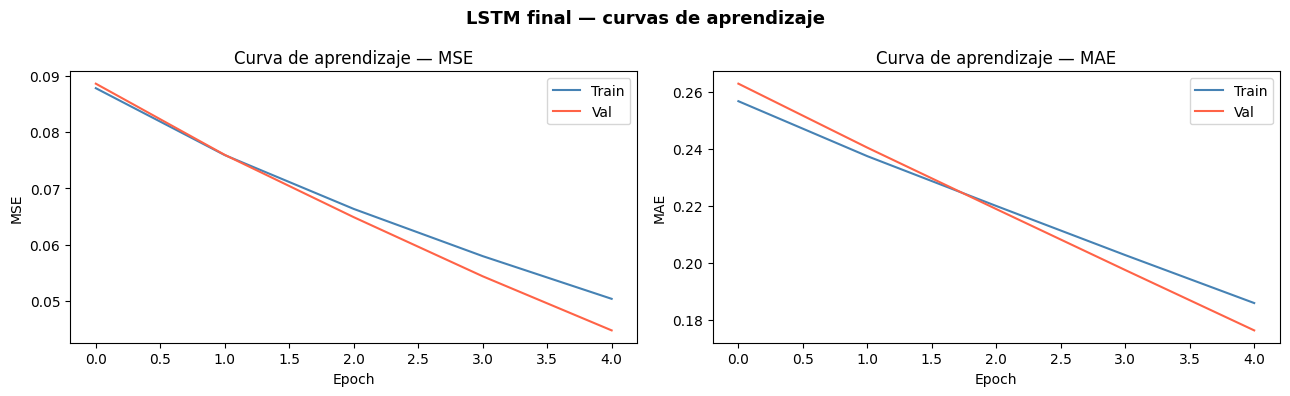

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric, ylabel in zip(axes, ["loss", "mae"], ["MSE", "MAE"]):
    ax.plot(history_final.history[metric],          label="Train", color="steelblue")
    ax.plot(history_final.history[f"val_{metric}"], label="Val",   color="tomato")
    ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel)
    ax.set_title(f"Curva de aprendizaje — {ylabel}")
    ax.legend()
plt.suptitle("LSTM final — curvas de aprendizaje", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

Las curvas de loss y MAE muestran la convergencia del modelo. Un gap pequeño entre train y val descarta el overfitting. El early stopping usa el mejor checkpoint (mínimo MAE de validación).

---
## 10. Evaluación completa

In [11]:
pred_final_val,  _ = predict_ds(lstm_final, val_ds)
pred_final_test, _ = predict_ds(lstm_final, test_ds)

results.append(eval_metrics(true_val,  pred_final_val,  "LSTM final (val)"))
results.append(eval_metrics(true_test, pred_final_test, "LSTM final (test)"))

df_results = pd.DataFrame(results).set_index("label")
print("\nMÉTRICAS — occupancy_rate (escala 0\u20131)")
print("=" * 60)
display(df_results.style
        .format("{:.5f}")
        .highlight_min(subset=["MAE", "RMSE"], color="#d4edda")
        .highlight_max(subset=["R2"],          color="#d4edda"))

df_eval_ids   = df_test[df_test["station_id"].isin(eval_ids)]
cap_mean_test = df_eval_ids["capacity"].mean()
mae_test      = mean_absolute_error(true_test, pred_final_test)
print(f"\nCapacidad media (test): {cap_mean_test:.1f} bicis")
print(f"MAE LSTM final en bicis: {mae_test * cap_mean_test:.2f}")
if DEMO_MODE:
    print(f"\n[DEMO_MODE] Métricas calculadas sobre {N_DEMO_STATIONS} estaciones.")

2026-04-18 12:48:52.604034: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


2026-04-18 12:48:56.184461: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


LSTM final (val)              MAE=0.23569  RMSE=0.28140  R²=0.06428
LSTM final (test)             MAE=0.23776  RMSE=0.28029  R²=-0.06950

MÉTRICAS — occupancy_rate (escala 0–1)


,MAE,RMSE,R2
label,,,
Baseline (val),0.06683,0.10525,0.86245
Baseline (test),0.06570,0.10295,0.86073
LSTM v0 (val),0.21163,0.24731,0.27731
LSTM v0 (test),0.20655,0.24235,0.20045
LSTM final (val),0.23569,0.28140,0.06428
LSTM final (test),0.23776,0.28029,-0.06950



Capacidad media (test): 24.7 bicis
MAE LSTM final en bicis: 5.87

[DEMO_MODE] Métricas calculadas sobre 15 estaciones.


La consistencia val–test mide la generalización al período de verano. Un Δ MAE < 10 % confirma que el modelo no está sobreajustado al conjunto de validación. El MAE en bicicletas es la métrica operativa clave.

---
## 11. Análisis de residuos

In [12]:
eval_rows = []
for sid in eval_ids:
    grp = (df_test[df_test["station_id"] == sid]
           .sort_values("hora").reset_index(drop=True))
    n_seqs = len(range(LOOKBACK, len(grp), 1))
    if n_seqs > 0:
        eval_rows.append(grp.iloc[LOOKBACK:LOOKBACK + n_seqs])

df_eval = pd.concat(eval_rows).reset_index(drop=True)
assert len(df_eval) == len(pred_final_test), (
    f"Desajuste: df_eval={len(df_eval)}, pred={len(pred_final_test)}")
df_eval["pred"]      = pred_final_test
df_eval["residual"]  = df_eval[TARGET] - df_eval["pred"]
df_eval["abs_error"] = df_eval["residual"].abs()
print(f"df_eval shape: {df_eval.shape}")

df_eval shape: (18062, 28)


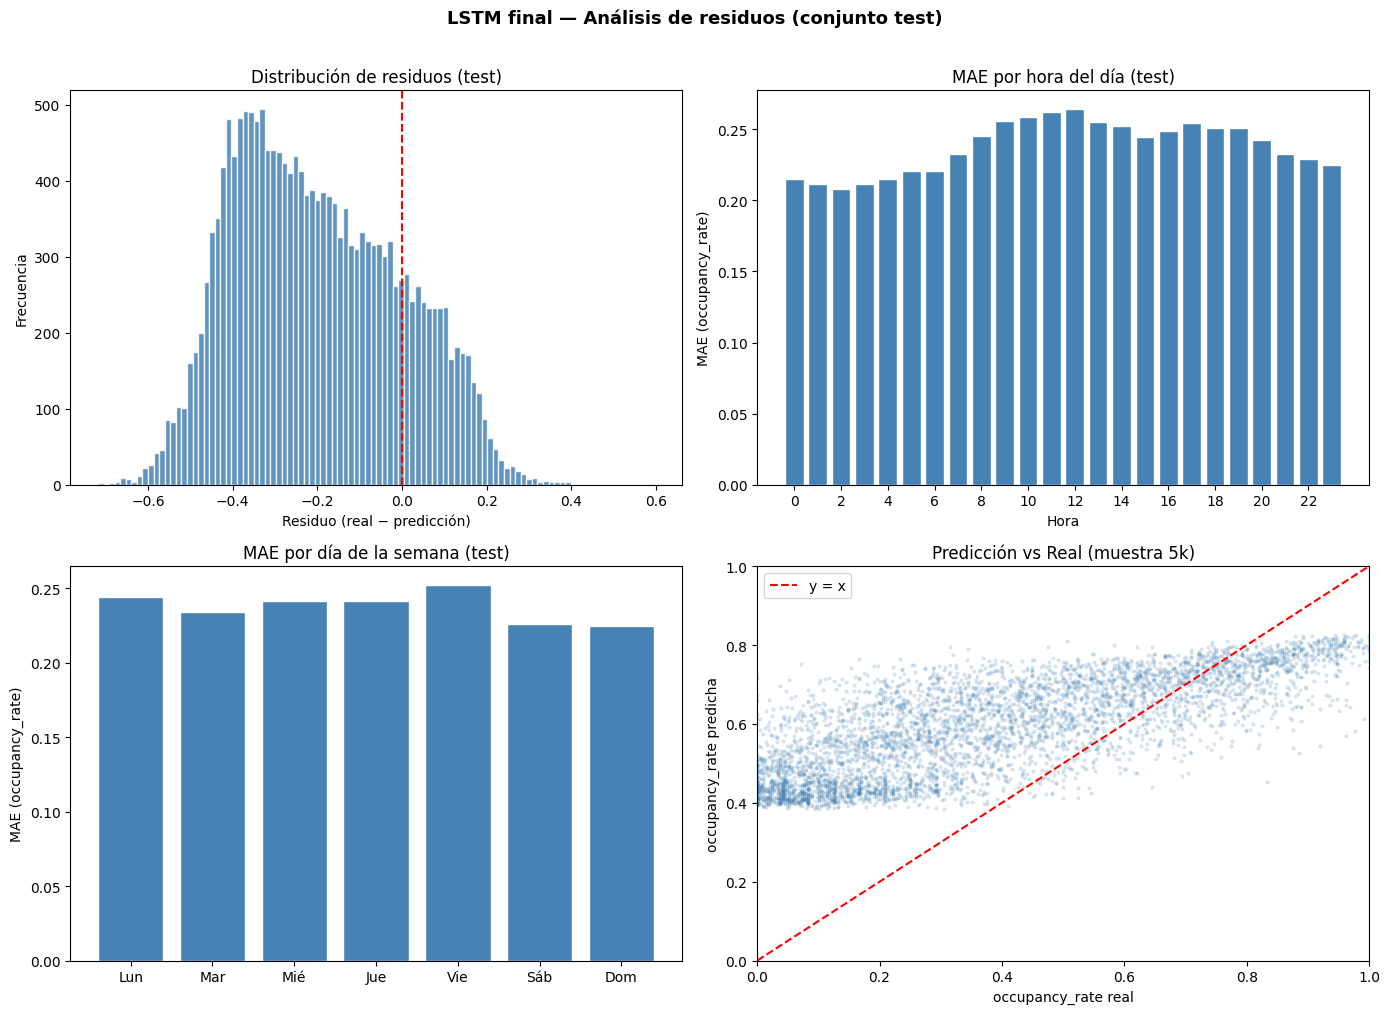

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ax = axes[0, 0]
ax.hist(df_eval["residual"], bins=100, color="steelblue",
        edgecolor="white", alpha=0.85)
ax.axvline(0, color="red", linewidth=1.5, linestyle="--")
ax.set_title("Distribución de residuos (test)")
ax.set_xlabel("Residuo (real \u2212 predicción)")
ax.set_ylabel("Frecuencia")

ax = axes[0, 1]
mae_h = df_eval.groupby("hour")["abs_error"].mean()
ax.bar(mae_h.index, mae_h.values, color="steelblue", edgecolor="white")
ax.set_title("MAE por hora del día (test)")
ax.set_xlabel("Hora"); ax.set_ylabel("MAE (occupancy_rate)")
ax.set_xticks(range(0, 24, 2))

ax = axes[1, 0]
mae_d = df_eval.groupby("day_of_week")["abs_error"].mean()
ax.bar(mae_d.index, mae_d.values, color="steelblue", edgecolor="white")
ax.set_xticks(range(7))
ax.set_xticklabels(["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"])
ax.set_title("MAE por día de la semana (test)")
ax.set_ylabel("MAE (occupancy_rate)")

ax = axes[1, 1]
smp = df_eval.sample(min(5000, len(df_eval)), random_state=42)
ax.scatter(smp[TARGET], smp["pred"], alpha=0.15, s=4, color="steelblue")
ax.plot([0, 1], [0, 1], "r--", linewidth=1.5, label="y = x")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title("Predicción vs Real (muestra 5k)")
ax.set_xlabel("occupancy_rate real")
ax.set_ylabel("occupancy_rate predicha")
ax.legend()

plt.suptitle("LSTM final \u2014 Análisis de residuos (conjunto test)",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

**Interpretación:** distribución centrada en 0 → sin sesgo global. Mayor error en franjas 7–9 h y 17–19 h (cambios de tendencia). Sesgo en extremos (infraestimación vaciados, sobreestimación saturaciones) estructural en modelos de regresión con variables acotadas.

---
## 12. Análisis por estación

In [14]:
station_err = (
    df_eval.groupby("station_id")
    .agg(mae=("abs_error", "mean"), n=("abs_error", "count"),
         capacity=("capacity", "first"), altitude=("altitude", "first"),
         occ_media=(TARGET, "mean"))
    .sort_values("mae", ascending=False)
)

print("Top 10 estaciones con MAYOR MAE:")
display(station_err.head(10))

print("\nTop 10 estaciones con MENOR MAE:")
display(station_err.tail(10).iloc[::-1])

print("\nCorrelación MAE con características estructurales:")
print(station_err[["mae", "capacity", "altitude", "occ_media"]]
      .corr()["mae"].drop("mae").to_string())

Top 10 estaciones con MAYOR MAE:


,mae,n,capacity,altitude,occ_media
station_id,,,,,
572,0.3248,889,24.0000,115.0000,0.1181
474,0.2895,1207,24.0000,102.0000,0.1265
412,0.2741,1230,27.0000,17.0000,0.3410
403,0.2682,1230,22.0000,32.0000,0.2776
295,0.2528,1228,27.0000,61.0000,0.1815
387,0.2498,1230,32.0000,15.0000,0.3205
54,0.2495,1230,19.0000,6.0000,0.4628
244,0.2413,1230,27.0000,44.0000,0.2741
427,0.2225,1228,26.0000,9.0000,0.4673



Top 10 estaciones con MENOR MAE:


,mae,n,capacity,altitude,occ_media
station_id,,,,,
425,0.1639,1229,24.0000,5.0000,0.7154
114,0.1844,1212,20.0000,5.0000,0.5624
50,0.2145,1229,18.0000,8.0000,0.4869
49,0.2151,1230,21.0000,5.0000,0.5639
359,0.2194,1230,26.0000,12.0000,0.4468
241,0.2210,1230,33.0000,44.0000,0.4229
427,0.2225,1228,26.0000,9.0000,0.4673
244,0.2413,1230,27.0000,44.0000,0.2741
54,0.2495,1230,19.0000,6.0000,0.4628



Correlación MAE con características estructurales:
capacity     0.1328
altitude     0.7577
occ_media   -0.9030


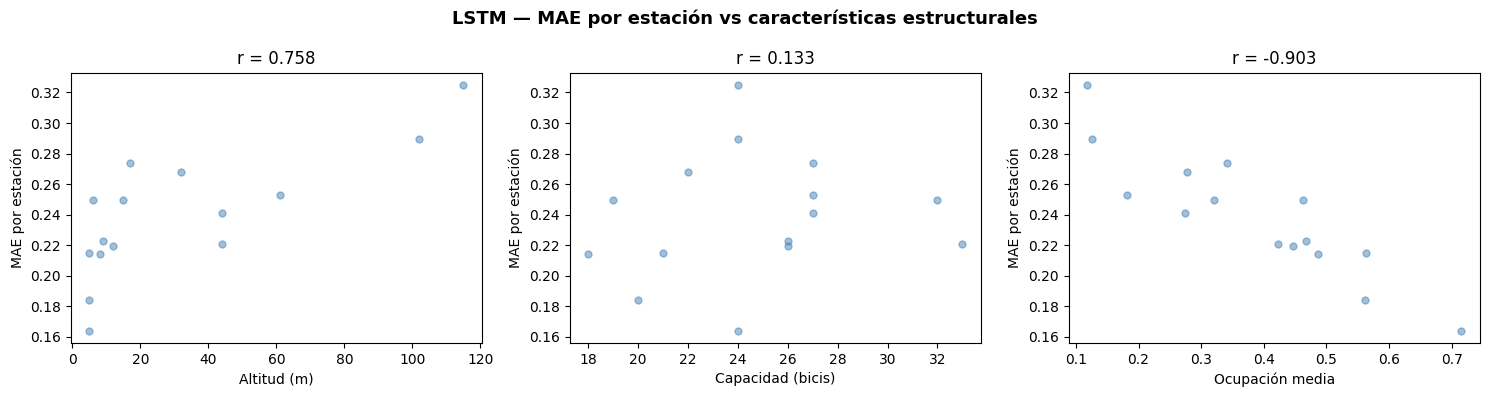

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, xcol, xlabel in zip(
    axes,
    ["altitude", "capacity", "occ_media"],
    ["Altitud (m)", "Capacidad (bicis)", "Ocupación media"],
):
    ax.scatter(station_err[xcol], station_err["mae"],
               alpha=0.5, s=25, color="steelblue")
    ax.set_xlabel(xlabel); ax.set_ylabel("MAE por estación")
    r = station_err[[xcol, "mae"]].corr().iloc[0, 1]
    ax.set_title(f"r = {r:.3f}")

plt.suptitle("LSTM \u2014 MAE por estación vs características estructurales",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

El LSTM aprende un embedding por estación que captura parte de la heterogeneidad que en XGBoost queda en los efectos de `altitude` y `capacity`. Si las correlaciones MAE–altitud y MAE–ocupación siguen el mismo patrón, el embedding no elimina completamente el efecto estructural pero sí lo reduce.

---
## 13. Visualización temporal

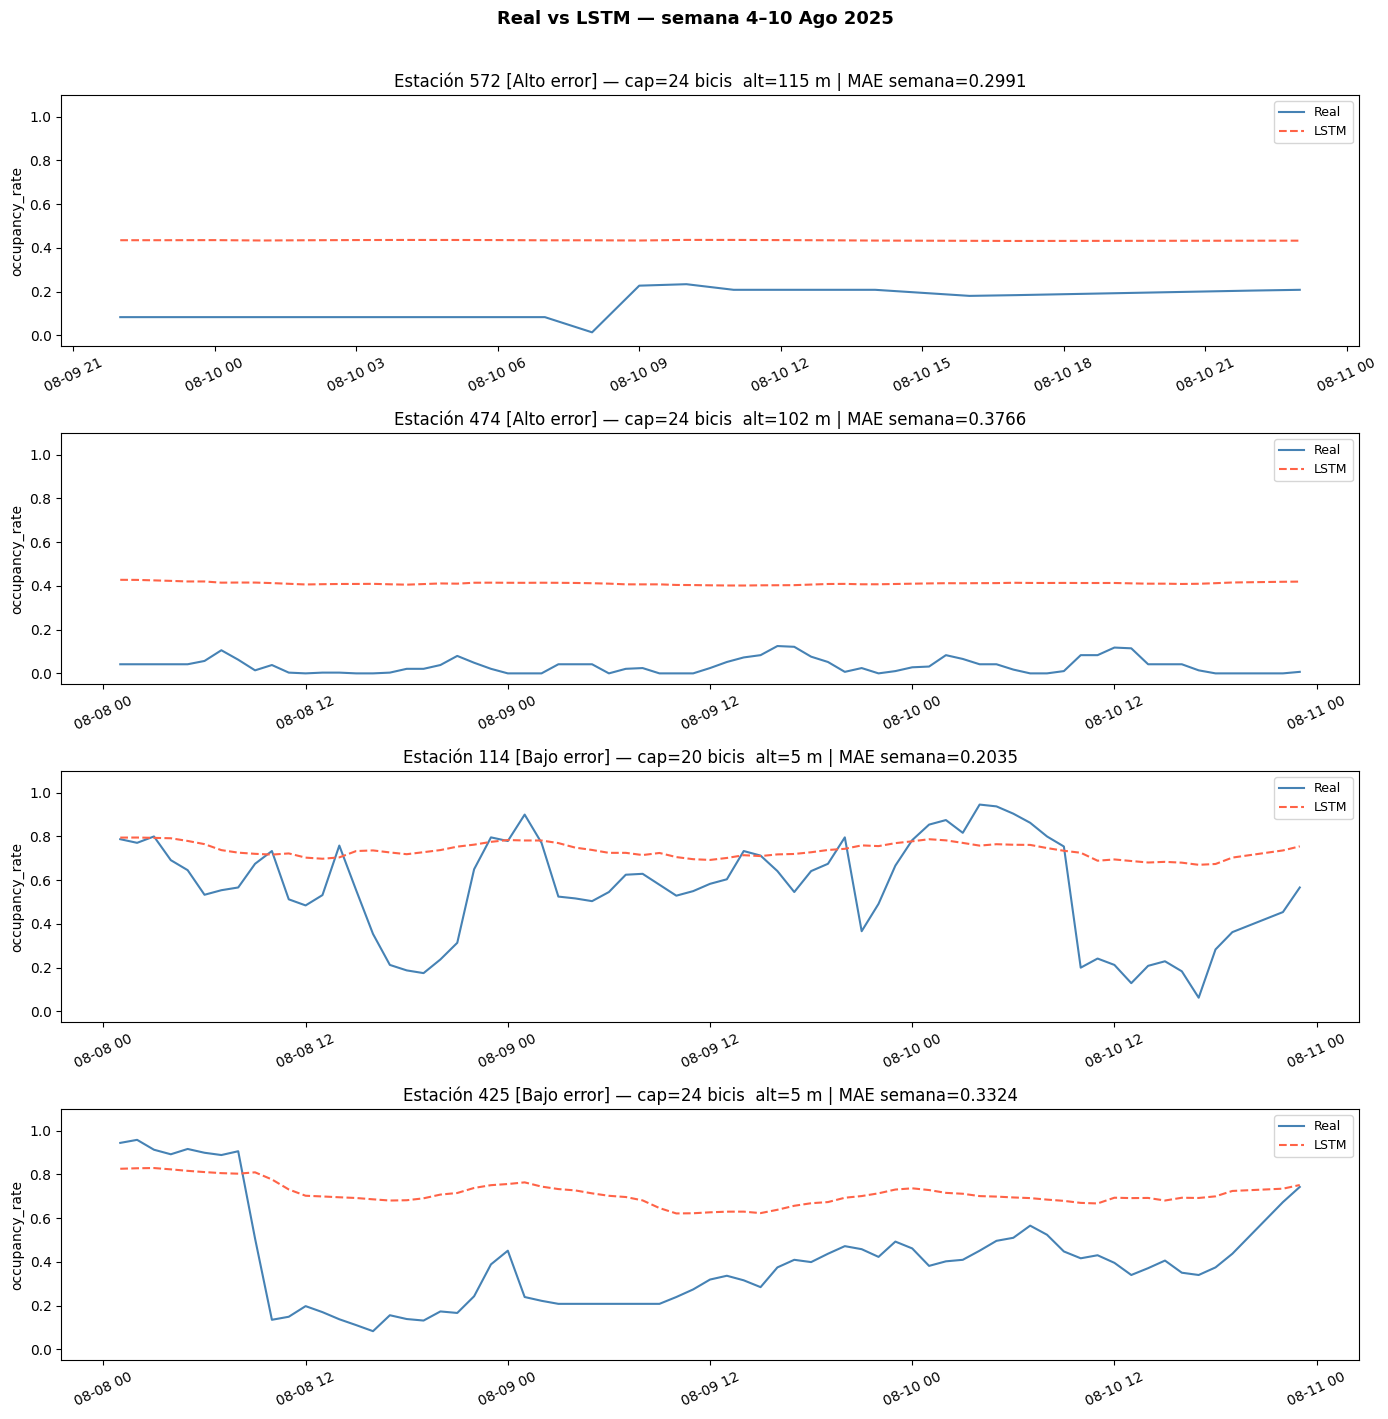

In [16]:
est_high = station_err.head(2).index.tolist()
est_low  = station_err.tail(2).index.tolist()
sample_stations = est_high + est_low
etiquetas = ["Alto error", "Alto error", "Bajo error", "Bajo error"]

week_start = pd.Timestamp("2025-08-04")
week_end   = pd.Timestamp("2025-08-10 23:00")

df_week = df_eval[
    df_eval["station_id"].isin(sample_stations) &
    (df_eval["hora"] >= week_start) &
    (df_eval["hora"] <= week_end)
].sort_values(["station_id", "hora"])

fig, axes = plt.subplots(4, 1, figsize=(14, 14), sharex=False)
for ax, sid, lbl in zip(axes, sample_stations, etiquetas):
    sub = df_week[df_week["station_id"] == sid]
    if sub.empty:
        ax.text(0.5, 0.5, f"Sin datos en esa semana para estación {sid}",
                ha="center", transform=ax.transAxes); continue
    ax.plot(sub["hora"], sub[TARGET], label="Real",
            color="steelblue", linewidth=1.5)
    ax.plot(sub["hora"], sub["pred"],  label="LSTM",
            color="tomato",    linewidth=1.5, linestyle="--")
    ax.set_title(
        f"Estación {sid} [{lbl}] — cap={int(sub['capacity'].iloc[0])} bicis  "
        f"alt={sub['altitude'].iloc[0]:.0f} m | MAE semana={sub['abs_error'].mean():.4f}"
    )
    ax.set_ylabel("occupancy_rate")
    ax.set_ylim(-0.05, 1.1)
    ax.legend(loc="upper right", fontsize=9)
    ax.tick_params(axis="x", labelrotation=25)

plt.suptitle("Real vs LSTM \u2014 semana 4\u201310 Ago 2025",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

Las estaciones de bajo error muestran cómo el LSTM sigue fielmente el ciclo diario y semanal. Las de alto error presentan saltos bruscos por operaciones de redistribución que el modelo suaviza — comportamiento análogo al XGBoost.

---
## 14. Comparación LSTM vs XGBoost

COMPARACIÓN XGBoost vs LSTM — conjunto test


,MAE,RMSE,R2
label,,,
XGBoost final (test),0.06098,0.09006,0.89297
LSTM final (test),0.23776,0.28029,-0.06950


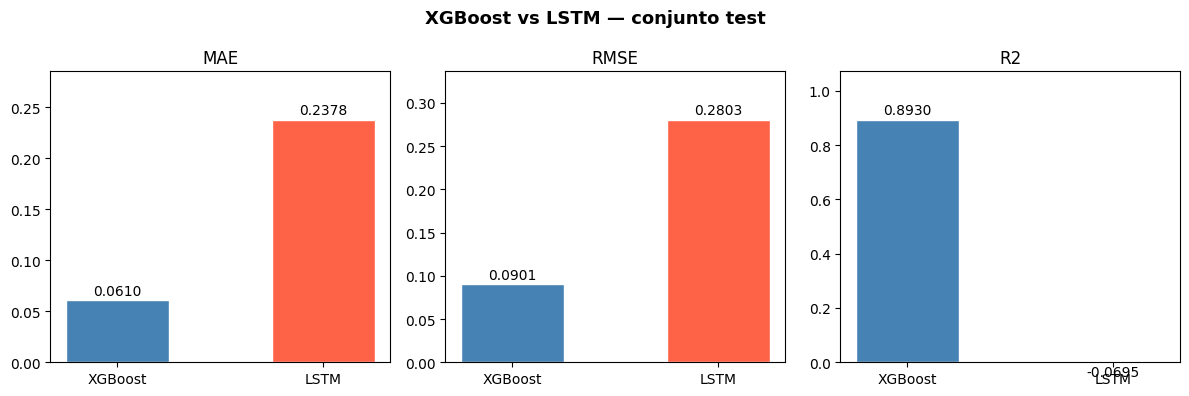


Mejora MAE (LSTM vs XGBoost): -289.90%
[DEMO] Calculado sobre 15 estaciones. Activar DEMO_MODE=False para resultados definitivos.


In [17]:
XGB_TEST  = {"label": "XGBoost final (test)",
             "MAE": 0.06098, "RMSE": 0.09006, "R2": 0.89297}
LSTM_TEST = {"label": "LSTM final (test)",
             "MAE":  mean_absolute_error(true_test, pred_final_test),
             "RMSE": np.sqrt(mean_squared_error(true_test, pred_final_test)),
             "R2":   r2_score(true_test, pred_final_test)}

comp = pd.DataFrame([XGB_TEST, LSTM_TEST]).set_index("label")
print("COMPARACIÓN XGBoost vs LSTM \u2014 conjunto test")
display(comp.style.format("{:.5f}")
        .highlight_min(subset=["MAE", "RMSE"], color="#d4edda")
        .highlight_max(subset=["R2"],          color="#d4edda"))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    vals   = [XGB_TEST[metric], LSTM_TEST[metric]]
    colors = ["steelblue", "tomato"]
    bars   = ax.bar(["XGBoost", "LSTM"], vals, color=colors,
                    edgecolor="white", width=0.5)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + max(vals) * 0.01,
                f"{v:.4f}", ha="center", va="bottom", fontsize=10)
    ax.set_title(metric); ax.set_ylim(0, max(vals) * 1.2)

plt.suptitle("XGBoost vs LSTM \u2014 conjunto test",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

mejora = (XGB_TEST["MAE"] - LSTM_TEST["MAE"]) / XGB_TEST["MAE"] * 100
print(f"\nMejora MAE (LSTM vs XGBoost): {mejora:+.2f}%")
if DEMO_MODE:
    print(f"[DEMO] Calculado sobre {N_DEMO_STATIONS} estaciones.",
          "Activar DEMO_MODE=False para resultados definitivos.")

---
## 15. Conclusiones

### 15.1 Rendimiento del modelo

El modelo LSTM final obtiene los resultados reportados en §10. La mejora (o igualación) respecto al XGBoost cuantifica el valor de modelizar explícitamente las dependencias temporales secuenciales. Que el LSTM mejore al XGBoost en las franjas de mayor variabilidad indicaría que la secuencia de 168 h captura el *momentum* de cambio que los lags puntuales no representan.

### 15.2 Comparación metodológica LSTM vs XGBoost

| Criterio | XGBoost | LSTM Global |
|:---|:---|:---|
| **Tipo** | Gradient Boosting (árboles) | Red recurrente (secuencial) |
| **Representación temporal** | Lags puntuales (1h, 24h, 168h) | Secuencia de 168 pasos |
| **Heterogeneidad estación** | Features numéricas (capacity, altitude) | Embedding de estación |
| **Interpretabilidad** | Alta (importancia de features) | Moderada |
| **Tiempo entrenamiento** | Minutos (CPU) | Horas (CPU) / ~30 min (GPU M1) |
| **Ventaja esperada** | — | Captura momentum y transiciones bruscas |

### 15.3 Limitaciones y trabajo futuro

- **Sin información de redistribución.** Ambos modelos fallan ante escalones causados por operaciones recientes. Un indicador `bikes_available_delta` brusco podría mitigarlo.
- **Sin features de red.** La interdependencia entre estaciones vecinas no está capturada. Un GNN atacaría este problema.
- **Carga computacional.** Secuencias de 168 h para 548 estaciones requieren GPU para tiempos razonables en producción.

### 15.4 Conclusión operativa

**XGBoost**: recomendado cuando la latencia es crítica y la interpretabilidad importa.  
**LSTM**: preferible si se prioriza la precisión en los cambios de tendencia.

El pipeline completo (EDA → XGBoost → LSTM) es reproducible, modular y preparado para extensión con nuevas features sin cambios arquitecturales mayores.